## Model Training

#### 1.1 Import Data and Required Packages
##### Importing Pandas, Numpy, Matplotlib, Seaborn and Warings Library.

In [21]:
# Basic Import
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
# Modelling
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge,Lasso
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import train_test_split
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
import warnings

#### Import the CSV Data as Pandas DataFrame

In [15]:
df = pd.read_csv('data/student_performance_cleaned.csv')

In [16]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


#### Preparing X and Y variables

In [17]:
# Drop individual scores and totals to prevent data leakage
X = df.drop(
    columns=[
        'math_score',
        'reading_score',
        'writing_score',
        'total_score',
        'average',
    ],
    errors='ignore',
)

# Define the target variable
y = df['average']

In [18]:
X.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course
0,female,group B,bachelor's degree,standard,none
1,female,group C,some college,standard,completed
2,female,group B,master's degree,standard,none
3,male,group A,associate's degree,free/reduced,none
4,male,group C,some college,standard,none


In [19]:
y

0      72.666667
1      82.333333
2      92.666667
3      49.333333
4      76.333333
         ...    
995    94.000000
996    57.333333
997    65.000000
998    74.333333
999    83.000000
Name: average, Length: 1000, dtype: float64

In [13]:
# As all our features are categorical, we'll encode them directly
encoder = OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False)
X_encoded = encoder.fit_transform(X)

In [20]:
X.shape

(1000, 5)

In [22]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)
X_train.shape, X_test.shape

((800, 12), (200, 12))

#### Create an Evaluate Function to give all metrics after model Training

In [23]:
def evaluate_model(true, predicted):
  mae = mean_absolute_error(true, predicted)
  mse = mean_squared_error(true, predicted)
  rmse = np.sqrt(mse)
  r2_square = r2_score(true, predicted)
  return mae, rmse, r2_square

In [24]:
# Initialize models dictionary
models = {
    'Linear Regression': LinearRegression(),
    'Lasso': Lasso(),
    'Ridge': Ridge(),
    'K-Neighbors Regressor': KNeighborsRegressor(),
    'Decision Tree': DecisionTreeRegressor(),
    'Random Forest Regressor': RandomForestRegressor(),
    'XGBRegressor': XGBRegressor(),
    'CatBoosting Regressor': CatBoostRegressor(verbose=False),
    'AdaBoost Regressor': AdaBoostRegressor(),
}

model_list = []
r2_list = []

# Train and evaluate each model
for model_name, model in models.items():
  # Fit model
  model.fit(X_train, y_train)

  # Make predictions
  y_train_pred = model.predict(X_train)
  y_test_pred = model.predict(X_test)

  # Evaluate training and test datasets
  model_train_mae, model_train_rmse, model_train_r2 = evaluate_model(
      y_train, y_train_pred
  )
  model_test_mae, model_test_rmse, model_test_r2 = evaluate_model(
      y_test, y_test_pred
  )

  print(model_name)
  model_list.append(model_name)

  print('Model performance for Training set')
  print('- Root Mean Squared Error: {:.4f}'.format(model_train_rmse))
  print('- Mean Absolute Error: {:.4f}'.format(model_train_mae))
  print('- R2 Score: {:.4f}'.format(model_train_r2))

  print('----------------------------------')

  print('Model performance for Test set')
  print('- Root Mean Squared Error: {:.4f}'.format(model_test_rmse))
  print('- Mean Absolute Error: {:.4f}'.format(model_test_mae))
  print('- R2 Score: {:.4f}'.format(model_test_r2))
  r2_list.append(model_test_r2)

  print('=' * 35)
  print('\n')

Linear Regression
Model performance for Training set
- Root Mean Squared Error: 12.1957
- Mean Absolute Error: 9.9361
- R2 Score: 0.2543
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 13.4016
- Mean Absolute Error: 10.4902
- R2 Score: 0.1622


Lasso
Model performance for Training set
- Root Mean Squared Error: 13.1964
- Mean Absolute Error: 10.5625
- R2 Score: 0.1269
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 14.1338
- Mean Absolute Error: 11.0886
- R2 Score: 0.0681


Ridge
Model performance for Training set
- Root Mean Squared Error: 12.1958
- Mean Absolute Error: 9.9359
- R2 Score: 0.2543
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 13.4068
- Mean Absolute Error: 10.4960
- R2 Score: 0.1615


K-Neighbors Regressor
Model performance for Training set
- Root Mean Squared Error: 11.7192
- Mean Absolute Error: 9.5687
- R2 Score: 0.3114
------------

### Results

In [25]:
pd.DataFrame(list(zip(model_list, r2_list)), columns=['Model Name', 'R2_Score']).sort_values(by=["R2_Score"],ascending=False)

,Model Name,R2_Score
0,Linear Regression,0.162172
2,Ridge,0.161521
8,AdaBoost Regressor,0.099455
1,Lasso,0.068120
7,CatBoosting Regressor,-0.002672
3,K-Neighbors Regressor,-0.014005
5,Random Forest Regressor,-0.029440
6,XGBRegressor,-0.036130
4,Decision Tree,-0.083037


## Linear Regression

In [26]:
lin_model = LinearRegression(fit_intercept=True)
lin_model = lin_model.fit(X_train, y_train)
y_pred = lin_model.predict(X_test)
score = r2_score(y_test, y_pred)*100
print(" Accuracy of the model is %.2f" %score)

 Accuracy of the model is 16.22


## Plot y_pred and y_test

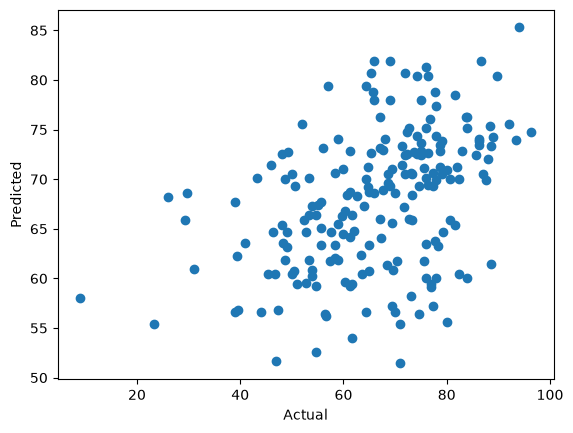

In [27]:
plt.scatter(y_test,y_pred);
plt.xlabel('Actual');
plt.ylabel('Predicted');

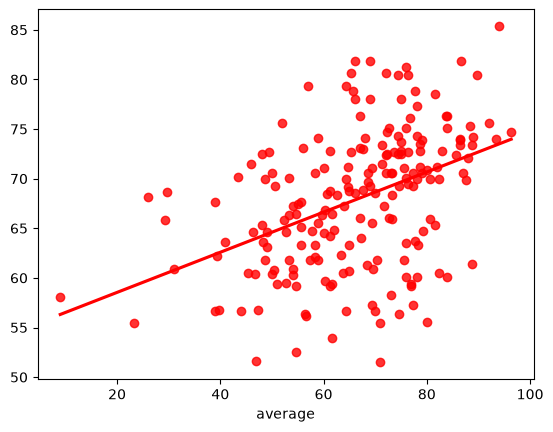

In [28]:
sns.regplot(x=y_test,y=y_pred,ci=None,color ='red');

#### Difference between Actual and Predicted Values

In [28]:
pred_df=pd.DataFrame({'Actual Value':y_test,'Predicted Value':y_pred,'Difference':y_test-y_pred})
pred_df

,Actual Value,Predicted Value,Difference
521,91,76.507812,14.492188
737,53,58.953125,-5.953125
740,80,76.960938,3.039062
660,74,76.757812,-2.757812
411,84,87.539062,-3.539062
...,...,...,...
408,52,43.546875,8.453125
332,62,62.031250,-0.031250
208,74,67.976562,6.023438
613,65,67.132812,-2.132812
